# Mumbai PM10: testing MVEN, GCEN and STEN against five baseline models

**What this notebook does**

We already **tuned** MVEN, GCEN and STEN (found their best hyperparameters on the validation period). Now we:

1. **Retrain** each model with its best hyperparameters on **training + validation** (everything before the test period).
2. **Forecast** the test period: the last **30 days** and the last **90 days** of 2024.
3. Do the same for five **baseline** models from the paper: DeepAR, Prob-iTransformer, GpGp, DiffSTG and STESN.
4. **Evaluate** every model with 14 metrics and build **one table** and **one figure** for the chapter.

Every model is trained **5 times** (seeds 1 to 5); the table shows the average and the standard deviation.

**What you get** (folder `Mumbai_PM10_testing`, plus a zip)

| File | Content |
|---|---|
| `table_evaluation.xlsx` / `.tex` / `.csv` | **Main table** (style of the paper's Tables 11 and 13): 8 models × 14 metrics × 2 horizons, mean (sd), best in **bold**, second best <u>underlined</u> |
| `figure_forecasts.png` / `.pdf` | **Main figure** (paper's Fig. 7): forecasts of MVEN, GCEN, STEN with 95 % intervals at 4 stations |
| `table_times.csv`, `metrics_per_seed.csv` | training times, and every seed's numbers |
| `figure_pit.png`, `figure_lag_importance.png`, `figure_station_weights.png` | extra figures (calibration, STEN's spatial lags, STEN's station weights) |
| `samples/` | every forecast (100 samples), saved as soon as a model is done |

**Before you run (on Kaggle)**
* **Add Input → Your Work**: the MVEN and STEN tuning outputs, the GCEN tuning outputs (method A: `short_1`, `long_1`), and, optionally, the output of the **GCEN comparison notebook** (then GCEN is not trained again).
* Settings: **Accelerator → GPU**, **Internet → On**.
* **Save Version → Save & Run All (Commit)**. Expect about 4 to 7 hours.
* If the session stops: attach this notebook's own output as an Input and run again. Finished models are not trained again.

---
# Part 1: Setup

## Cell 1: Install packages
* `stengression`: MVEN, GCEN, STEN (the paper's package)
* `darts`: DeepAR, `gluonts`: Prob-iTransformer, `easydict`: needed by the DiffSTG code

In [1]:
import subprocess, sys

def pip_install(package):
    result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], capture_output=True)
    return result.returncode == 0

for module, package in [("stengression", "stengression"), ("darts", "darts"), ("gluonts", "gluonts[torch]"),
                        ("lightning", "lightning"), ("easydict", "easydict"), ("openpyxl", "openpyxl")]:
    try:
        __import__(module)
        print(f"{package}: already installed")
    except ImportError:
        print(f"{package}: installing ...", "ok" if pip_install(package) else "FAILED")

stengression: installing ... ok
darts: installing ... ok
gluonts[torch]: installing ... ok
lightning: already installed
easydict: already installed
openpyxl: already installed


## Cell 2: Import packages

In [2]:
import os, glob, json, time, shutil, warnings, logging, platform, types, importlib.util, contextlib, io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from stengression import (MVEN, STEN, GCEN, GraphInfo, energy_score_loss, SpatioTemporalDataset,
                          prepare_spatial_weights, compute_adjacency_matrix)

warnings.filterwarnings("ignore")                       # hide harmless warnings
for name in ["lightning", "lightning.pytorch", "lightning.fabric", "lightning.pytorch.utilities.rank_zero",
             "lightning.pytorch.accelerators.cuda", "pytorch_lightning", "darts", "gluonts"]:
    logging.getLogger(name).setLevel(logging.ERROR)     # keep training logs short

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running on:", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

Running on: cuda | Tesla T4


## Cell 3: Settings
These are the paper's settings. **Don't change them** for the real run.
* `RUN_MODELS`: which models to run in this session (you can split the work over two sessions).
* `GCEN_METHOD`: which GCEN tuning to use (`"A"` = complete graph).
* `QUICK_RUN = True` only checks that every cell works (results are then meaningless).

In [3]:
# ---------- forecasting setup (paper) ----------
HORIZONS  = [30, 90]          # forecast the last 30 days and the last 90 days
VAL_LENS  = {30: 60, 90: 120} # validation length (only DiffSTG uses it, for early stopping)
LOOKBACK  = 60                # every model sees the last 60 days
SEEDS     = [1, 2, 3, 4, 5]   # 5 training runs per model
EPOCHS    = 100               # training epochs for MVEN / GCEN / STEN
BATCH     = 64
N_SAMPLES = 100               # forecast samples (possible futures) per forecast
N_REPEATS = 50                # MVEN / GCEN / STEN: each seed's score = average of 50 forecasts (paper)

# ---------- which models ----------
RUN_MODELS  = ["MVEN", "GCEN", "STEN", "DeepAR", "Prob-iTransformer", "GpGp", "DiffSTG", "STESN"]
GCEN_METHOD = "A"             # "A" = complete graph, "B" = 10-km graph

# ---------- baseline settings (each model's own default values) ----------
DEEPAR_EPOCHS  = 100
ITRANS_EPOCHS  = 100
DIFFSTG_EPOCHS = 300          # with early stopping
DIFFSTG_STEPS  = 200          # diffusion steps
STESN_HP       = [1, 2500, 0.150, 0.90, 1.00, 0.05, 0.01, 0.10, 0.01]   # published: m, n_h, lambda, delta, phi, a_w, a_u, pi_w, pi_u
STESN_MEMBERS  = 100          # 100 reservoirs = 100 forecast samples
GPGP_MAX_ITER  = 40

QUICK_RUN = False
if QUICK_RUN:
    SEEDS, EPOCHS, N_REPEATS = [1, 2], 2, 2
    DEEPAR_EPOCHS, ITRANS_EPOCHS, DIFFSTG_EPOCHS, DIFFSTG_STEPS = 1, 1, 1, 50
    STESN_HP = [1, 100] + STESN_HP[2:]; STESN_MEMBERS = 20; GPGP_MAX_ITER = 2
    print("QUICK_RUN is on: results are NOT meaningful")

# ---------- folders ----------
BASE = Path("/kaggle/working") if os.path.isdir("/kaggle/working") else Path("outputs")
OUT_DIR = BASE / "Mumbai_PM10_testing"          # results (saved)
SAMPLE_DIR = OUT_DIR / "samples"
SCRATCH = Path("/tmp/pm10_testing")             # temporary files (not saved)
SAMPLE_DIR.mkdir(parents=True, exist_ok=True); SCRATCH.mkdir(parents=True, exist_ok=True)

ENGRESSION = ["MVEN", "GCEN", "STEN"]
BASELINES = ["DeepAR", "Prob-iTransformer", "GpGp", "DiffSTG", "STESN"]
MODEL_ORDER = BASELINES + ENGRESSION            # column order of the table
print("Results folder:", OUT_DIR)

Results folder: /kaggle/working/Mumbai_PM10_testing


---
# Part 2: Data and tuned hyperparameters

## Cell 4: Load the PM10 data
1461 days (2021-01-01 to 2024-12-31) × 17 stations. The file has no dates, so we add them; the columns are matched to the station list by order.
Files are taken from the Kaggle inputs if attached, otherwise downloaded from GitHub.

In [4]:
GITHUB = "https://raw.githubusercontent.com/ctanujit/GraphSVR/main/Data/"

def load_csv(file_name):
    found = glob.glob(f"/kaggle/input/**/{file_name}", recursive=True) + glob.glob(f"**/{file_name}", recursive=True)
    return pd.read_csv(found[0]) if found else pd.read_csv(GITHUB + file_name)

raw = load_csv("Mumbai_PM10_Data.csv")
stations = load_csv("Mumbai_Stations_PM10.csv").iloc[:, :3].dropna().reset_index(drop=True)
stations.columns = ["Station", "LAT", "LONG"]

import hashlib
data_md5 = hashlib.md5(raw.to_csv(index=False).encode()).hexdigest()   # fingerprint, to check the tuning used the same data

data = raw.copy()
data.columns = stations["Station"]
data.index = pd.date_range("2021-01-01", periods=len(data), freq="D")
station_names = list(data.columns)

Y = data.values.astype(np.float32)     # (days, stations)
T, N = Y.shape
print(f"{T} days x {N} stations")
data.head(3)

1461 days x 17 stations


Station,"Boriwali East,IITM","Boriwali East,MPCB",Chakala-Andheri East,"Chhatrapati International Airport,Terminal 2",Colaba,"Deonar,IITM","Kandiwali East,MPCB",Khinipada-Bhandup West,Kurla,Malad West,Mazgaon,Mulund West,"Navy Nagar,Colaba",Powai,Sion,Vile Parle West,"Worli,MPCB"
2021-01-01,216.09,174.48,256.81,251.71,106.18,219.51,214.65,136.50,304.43,273.21,251.63,199.82,135.36,169.00,278.91,256.40,204.840000
2021-01-02,252.70,201.75,265.89,290.14,104.89,223.46,243.00,176.34,353.76,193.96,174.81,237.37,115.12,192.79,260.12,239.42,200.780000
2021-01-03,240.02,196.69,259.12,259.06,81.60,216.50,226.36,158.47,290.08,244.88,188.25,216.79,105.38,185.68,263.01,218.12,192.273073


## Cell 5: Distances between stations (km)
Used by STEN (spatial weights), GCEN and DiffSTG (graph) and GpGp (locations).

In [5]:
lat = np.radians(stations["LAT"].values)
lon = np.radians(stations["LONG"].values)
a = (np.sin((lat[:, None] - lat[None, :]) / 2) ** 2
     + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin((lon[:, None] - lon[None, :]) / 2) ** 2)
dist = 2 * 6371 * np.arcsin(np.sqrt(a))          # Haversine distance, (17, 17)
print(f"Distances between stations: {dist[dist > 0].min():.1f} to {dist.max():.1f} km")

Distances between stations: 1.0 to 37.7 km


## Cell 6: Find gap-filled values
Some missing days in the data were filled with straight lines. We keep them (data used as published), but we note where they are, so the figure can show stations with real measurements in the test period.

In [6]:
def straight_line_days(series, min_len=5):
    flat = (series.diff().diff().abs() < 1e-4).values        # second difference = 0 -> straight line
    mask = np.zeros(len(series), bool)
    i = 0
    while i < len(series):
        if flat[i]:
            j = i
            while j < len(series) and flat[j]:
                j += 1
            if j - (i - 2) >= min_len:
                mask[max(i - 2, 0):j] = True
            i = j
        else:
            i += 1
    return mask

gap_filled = pd.DataFrame({s: straight_line_days(data[s]) for s in station_names}, index=data.index)
in_test = gap_filled.iloc[-90:].sum()
print("Stations with gap-filled values in the last 90 days:", dict(in_test[in_test > 0]))

Stations with gap-filled values in the last 90 days: {'Chakala-Andheri East': np.int64(90), 'Deonar,IITM': np.int64(11), 'Malad West': np.int64(33), 'Sion': np.int64(5), 'Worli,MPCB': np.int64(7)}


## Cell 7: Read the tuned hyperparameters
* MVEN and STEN: `best_hyperparameters_MVEN.json` and `best_hyperparameters_STEN.json` (both horizons in one file).
* GCEN: `best_params_short.json` (30 days) and `best_params_long.json` (90 days), method chosen by `GCEN_METHOD`.

The cell checks that the tuning used **the same data file** (fingerprint) and stops with a message if a file is missing.

In [7]:
BEST = {}           # BEST[model][horizon] = dictionary of hyperparameters
GCEN_SETTINGS = {}  # GCEN graph and noise settings per horizon
summary = []

# ---- MVEN and STEN ----
for file in glob.glob("/kaggle/input/**/best_hyperparameters_*.json", recursive=True) + glob.glob("**/best_hyperparameters_*.json", recursive=True):
    if "Mumbai_PM10_testing" in file:
        continue
    info = json.load(open(file))
    assert info["data_md5"] == data_md5, f"{file} was tuned on a different data file"
    for h, res in info["horizons"].items():
        BEST.setdefault(info["model"], {})[int(h)] = res["params"]
        summary.append({"model": info["model"], "horizon": int(h), "validation CRPS": round(res["best_val_crps"], 2),
                        "tuning complete": res["complete"], "file": file})

# ---- GCEN ----
for file in glob.glob("/kaggle/input/**/best_params_*.json", recursive=True) + glob.glob("**/best_params_*.json", recursive=True):
    info = json.load(open(file))
    fp = info.get("fingerprint", {})
    if fp.get("DATASET") != "Mumbai_PM10":
        continue
    method = "A" if fp["DIST_SCALE_KM"] >= 1000 else "B"     # A = complete graph, B = 10-km graph
    if method != GCEN_METHOD:
        continue
    h = int(fp["H"])
    BEST.setdefault("GCEN", {})[h] = info["best_params"]
    GCEN_SETTINGS[h] = fp
    summary.append({"model": "GCEN", "horizon": h, "validation CRPS": round(info["best_value"], 2),
                    "tuning complete": info.get("finished_trials", 0) >= 100, "file": file})

summary = pd.DataFrame(summary).drop_duplicates(["model", "horizon"]).sort_values(["model", "horizon"])
display(summary)

for m in ENGRESSION:
    if m in RUN_MODELS:
        for h in HORIZONS:
            assert h in BEST.get(m, {}), f"No tuned hyperparameters for {m}, {h}-day horizon: attach its tuning output"
print("Tuned hyperparameters found for every model and horizon.")

,model,horizon,validation CRPS,tuning complete,file
5,GCEN,30,23.21,True,/kaggle/input/datasets/safeeth/final-testing-t...
4,GCEN,90,16.91,True,/kaggle/input/datasets/safeeth/final-testing-t...
0,MVEN,30,18.36,True,/kaggle/input/datasets/safeeth/final-testing-t...
1,MVEN,90,17.80,True,/kaggle/input/datasets/safeeth/final-testing-t...
2,STEN,30,18.69,True,/kaggle/input/datasets/safeeth/final-testing-t...
3,STEN,90,16.37,True,/kaggle/input/datasets/safeeth/final-testing-t...


Tuned hyperparameters found for every model and horizon.


## Cell 8: Training data for each horizon
* **Test period** = the last 30 (or 90) days. No model sees it during training.
* **Training data** = everything before the test period (= training + validation).
* For MVEN / GCEN / STEN each station is standardised with the mean and sd of the training data, and the data is cut into windows: 60 days in → 30 (or 90) days out.

In [8]:
prep = {}
for h in HORIZONS:
    test_start = T - h
    train = torch.tensor(Y[:test_start]).unsqueeze(-1)              # (days, stations, 1)
    mean, std = train.mean(0), train.std(0)
    train_scaled = (train - mean) / std
    prep[h] = {
        "test_start": test_start,
        "val_start": test_start - VAL_LENS[h],
        "mean": mean, "std": std,
        "loader": DataLoader(SpatioTemporalDataset(train_scaled, LOOKBACK, h), batch_size=BATCH, shuffle=False),
        "last_60_scaled": train_scaled[-LOOKBACK:],                  # input for the test forecast
        "y_train": Y[:test_start],                                   # original scale
        "y_test": Y[test_start:],
    }
    print(f"{h}-day horizon: train {data.index[0].date()} to {data.index[test_start - 1].date()}, "
          f"test {data.index[test_start].date()} to {data.index[-1].date()}")

30-day horizon: train 2021-01-01 to 2024-12-01, test 2024-12-02 to 2024-12-31
90-day horizon: train 2021-01-01 to 2024-10-02, test 2024-10-03 to 2024-12-31


---
# Part 3: Tools used by every model

## Cell 9: Evaluation metrics
Compares the 100 forecast samples with the observed test values (all days and stations, in µg/m³).

| Metric | What it measures | Better |
|---|---|---|
| SMAPE, MAE, RMSE | error of the median forecast | lower |
| MASE, RMSSE | the same, relative to a naive "tomorrow = today" forecast | lower |
| Pinball-80, Pinball-95 | quality of the 80 % and 95 % quantiles | lower |
| ρ-0.5, ρ-0.9 Risk | quality of the median and 90 % quantile | lower |
| CRPS | quality of the whole forecast distribution (main metric) | lower |
| Winkler | 95 % interval width + penalty when the truth is outside | lower |
| Coverage | share of observed values inside the 95 % interval | close to 0.95 |
| Width | average width of the 95 % interval | narrower, if coverage is fine |
| Energy score | the whole forecast of all stations and days together | lower |

In [9]:
METRICS = ["SMAPE", "MAE", "RMSE", "MASE", "RMSSE", "Pinball_80", "Pinball_95", "Rho_05", "Rho_09",
           "CRPS", "Winkler_95", "Coverage_95", "Width_95", "Energy_score"]
LABELS = {"SMAPE": "SMAPE", "MAE": "MAE", "RMSE": "RMSE", "MASE": "MASE", "RMSSE": "RMSSE",
          "Pinball_80": "Pinball-80", "Pinball_95": "Pinball-95", "Rho_05": "ρ-0.5 Risk", "Rho_09": "ρ-0.9 Risk",
          "CRPS": "CRPS", "Winkler_95": "Winkler Score", "Coverage_95": "Coverage (95%)",
          "Width_95": "Interval width (95%)", "Energy_score": "Energy score"}

def evaluate(samples, truth, train):
    S = torch.tensor(np.asarray(samples), dtype=torch.float64)      # (100, days, stations)
    y = torch.tensor(np.asarray(truth), dtype=torch.float64)        # (days, stations)
    tr = torch.tensor(np.asarray(train), dtype=torch.float64)

    median = S.median(0).values
    error = median - y
    q = lambda p: torch.quantile(S, p, dim=0)
    low, high = q(0.025), q(0.975)
    naive_abs = (tr[1:] - tr[:-1]).abs().mean()
    naive_sq = ((tr[1:] - tr[:-1]) ** 2).mean()

    def pinball(p):
        return torch.maximum(p * (y - q(p)), (p - 1) * (y - q(p))).mean()
    def rho_risk(p):
        loss = torch.where(y > q(p), 2 * p * (y - q(p)), 2 * (1 - p) * (q(p) - y))
        return loss.sum() / y.abs().sum()

    crps = ((S - y).abs().mean(0) - 0.5 * (S[:, None] - S[None]).abs().mean((0, 1))).mean()
    flat = S.reshape(len(S), -1)
    energy = (flat - y.reshape(1, -1)).norm(dim=1).mean() - 0.5 * torch.cdist(flat, flat).mean()
    winkler = (high - low) + 40 * (low - y).clamp(min=0) + 40 * (y - high).clamp(min=0)

    result = {"SMAPE": (error.abs() / ((median.abs() + y.abs()) / 2).clamp(min=1e-8)).mean() * 100,
              "MAE": error.abs().mean(), "RMSE": (error ** 2).mean().sqrt(),
              "MASE": error.abs().mean() / naive_abs, "RMSSE": ((error ** 2).mean() / naive_sq).sqrt(),
              "Pinball_80": pinball(0.8), "Pinball_95": pinball(0.95),
              "Rho_05": rho_risk(0.5), "Rho_09": rho_risk(0.9), "CRPS": crps, "Winkler_95": winkler.mean(),
              "Coverage_95": ((y >= low) & (y <= high)).double().mean(), "Width_95": (high - low).mean(),
              "Energy_score": energy}
    return {k: float(v) for k, v in result.items()}

## Cell 10: Save and load results
Each finished model run (model × horizon × seed) is saved at once as `samples/<model>_H<horizon>_seed<seed>.npz`. If that file already exists (also from an attached earlier output), the run is **skipped**. This is what makes resuming possible.

In [10]:
# copy finished runs from an attached earlier output
for f in glob.glob("/kaggle/input/**/samples/*_H*_seed*.npz", recursive=True):
    if not (SAMPLE_DIR / Path(f).name).exists():
        shutil.copy(f, SAMPLE_DIR / Path(f).name)

def result_file(model, h, seed):
    return SAMPLE_DIR / f"{model}_H{h}_seed{seed}.npz"

def save_result(model, h, seed, samples, metrics, train_sec, extra=None):
    np.savez_compressed(result_file(model, h, seed), samples=np.asarray(samples, dtype=np.float32),
                        metrics=json.dumps(metrics), train_sec=train_sec, extra=json.dumps(extra or {}))

def load_result(model, h, seed):
    z = np.load(result_file(model, h, seed))
    return {"samples": z["samples"], "metrics": json.loads(str(z["metrics"])),
            "train_sec": float(z["train_sec"]), "extra": json.loads(str(z["extra"]))}

def report(model, h, seed, metrics, train_sec):
    print(f"{model:18s} H={h} seed={seed}:  CRPS {metrics['CRPS']:7.2f}   MAE {metrics['MAE']:7.2f}   "
          f"coverage {metrics['Coverage_95']:.2f}   train {train_sec / 60:.1f} min")

## Cell 11: Run a baseline for every horizon and seed
`run_baseline(name, train_and_forecast)` loops over horizons and seeds, skips finished runs, scores the forecast and saves it. If a baseline crashes (e.g. a package can't be installed), the error is printed and its column stays empty; the notebook continues.

In [11]:
FAILED = {}

def run_baseline(name, train_and_forecast):
    if name not in RUN_MODELS:
        print(f"{name}: not in RUN_MODELS, skipped"); return
    for h in HORIZONS:
        for seed in SEEDS:
            if result_file(name, h, seed).exists():
                print(f"{name} H={h} seed={seed}: already done"); continue
            try:
                samples, train_sec, extra = train_and_forecast(h, seed)      # (100, h, 17), seconds, info
                metrics = evaluate(samples, prep[h]["y_test"], prep[h]["y_train"])
                save_result(name, h, seed, samples, metrics, train_sec, extra)
                report(name, h, seed, metrics, train_sec)
            except Exception as e:
                FAILED[name] = f"{type(e).__name__}: {e}"
                print(f"{name} FAILED: {FAILED[name]}"); return

def shell(cmd, timeout=3600):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True, timeout=timeout)
    return r.returncode == 0, r.stdout + r.stderr

---
# Part 4: MVEN, GCEN and STEN (our models)

## Cell 12: STEN's spatial weights
STEN mixes each station with its neighbours, weighted by distance: $W_{ij} = 1/d_{ij}^{\alpha}$, each row scaled to sum to 1.
`prepare_spatial_weights` returns $[I, W, W^2, \dots, W^L]$: the station itself, its neighbours, the neighbours' neighbours, ...
α and L were tuned.

In [12]:
def sten_weights(alpha, L):
    W = 1.0 / np.where(dist == 0, np.inf, dist) ** alpha     # closer = larger weight, itself = 0
    W = W / W.sum(1, keepdims=True)                          # each row sums to 1
    return [w.to(device) for w in prepare_spatial_weights(torch.tensor(W, dtype=torch.float32), L)]

## Cell 13: GCEN's graph
Built exactly as in GCEN's tuning. With method A (`DIST_SCALE_KM` = 10 000) every pair of stations is connected (complete graph). Each station is also connected to itself.

In [13]:
GCEN_ADJ = {}
for h, fp in GCEN_SETTINGS.items():
    GCEN_ADJ[h] = compute_adjacency_matrix(dist, fp["SIGMA2"], fp["EPSILON"], fp["DIST_SCALE_KM"])
    print(f"GCEN graph, {h}-day: {int(GCEN_ADJ[h][np.triu_indices(N, 1)].sum())} of {N * (N - 1) // 2} station pairs connected")

def gcen_graph(h):
    A = GCEN_ADJ[h] + np.eye(N)                       # + self-loops
    rows, cols = np.where(A > 0)
    return GraphInfo(edges=(rows.tolist(), cols.tolist()), num_nodes=N)

GCEN graph, 90-day: 136 of 136 station pairs connected
GCEN graph, 30-day: 136 of 136 station pairs connected


## Cell 14: Build a model with its tuned hyperparameters
Returns a new, untrained model and (for STEN) its spatial weights.

In [14]:
def build_model(name, h, seed):
    hp = BEST[name][h]
    if name == "MVEN":
        model = MVEN(in_feat_dim=1, num_nodes=N, lstm_hidden_dim=hp["hidden"], lstm_num_layers=hp["layers"],
                     lstm_dropout=hp["dropout"] if hp["layers"] > 1 else 0.0,
                     p_lag=LOOKBACK, t_pred=h, noise_dist=hp["noise_dist"])
        return model.to(device), None
    if name == "STEN":
        model = STEN(in_feat_dim=1, num_nodes=N, embedding_dim=hp["emb_dim"], max_spatial_lag=hp["L"],
                     lstm_hidden_dim=hp["hidden"], lstm_num_layers=hp["layers"],
                     lstm_dropout=hp["dropout"] if hp["layers"] > 1 else 0.0,
                     p_lag=LOOKBACK, t_pred=h, noise_dist=hp["noise_dist"])
        return model.to(device), sten_weights(hp["alpha"], hp["L"])
    if name == "GCEN":
        fp = GCEN_SETTINGS[h]
        model = GCEN(in_feat_dim=1, gcn_out_feat=hp["gcn_out_feat"], lstm_hidden_dim=hp["lstm_hidden_dim"],
                     lstm_num_layers=hp["lstm_num_layers"],
                     lstm_dropout=hp["lstm_dropout"] if hp["lstm_num_layers"] > 1 else 0.0,
                     p_lag=LOOKBACK, t_pred=h, graph_info=gcen_graph(h), noise_dist=hp["noise_dist"],
                     noise_encode=fp.get("NOISE_ENCODE", "add"), noise_std=fp.get("NOISE_STD", 1.0),
                     graph_conv_params=fp.get("GRAPH_CONV"),
                     gcn_seed=fp.get("GCN_SEED_BASE", 21) + seed, temporal_seed=fp.get("TEMPORAL_SEED_BASE", 9) + seed)
        return model.to(device), None

## Cell 15: Train, forecast and evaluate one of our models
For one model, horizon and seed:
1. build the model and **train it on training + validation** for 100 epochs (energy score loss, 2 samples per step);
2. **forecast the test period** 50 times, each time with 100 samples (100 different noise draws = 100 possible futures);
3. score each forecast and **average** the 50 scores (paper's protocol). The first forecast is saved for the figures.

For STEN, the size of the learned spatial weights ‖Φₗ‖ is also saved (spatial lag importance, paper's Fig. 11).

In [15]:
def run_engression(name, h, seed):
    p = prep[h]
    torch.manual_seed(seed); np.random.seed(seed)
    model, W = build_model(name, h, seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=BEST[name][h]["lr"])

    # 1. train on training + validation
    start = time.time()
    if name == "STEN":
        model.fit(p["loader"], optimizer, energy_score_loss, W, num_epochs=EPOCHS, m_samples=2,
                  device=device, monitor=False, visualize=False)
    else:
        model.fit(p["loader"], optimizer, energy_score_loss, num_epochs=EPOCHS, m_samples=2,
                  device=device, monitor=False, visualize=False)
    train_sec = time.time() - start

    # 2. forecast the test period: 100 copies of the last 60 days -> 100 futures
    model.eval()
    x = p["last_60_scaled"].unsqueeze(0).repeat(N_SAMPLES, 1, 1, 1).to(device)
    torch.manual_seed(1000 + seed)
    scores, first = [], None
    with torch.no_grad():
        for r in range(N_REPEATS):
            out = model(x, W) if name == "STEN" else model(x)
            samples = (out.cpu() * p["std"] + p["mean"])[..., 0].numpy()      # back to µg/m³, (100, h, 17)
            scores.append(evaluate(samples, p["y_test"], p["y_train"]))      # 3. score
            if r == 0:
                first = samples
    metrics = pd.DataFrame(scores).mean().to_dict()                         # average of the 50 forecasts

    extra = {"hyperparameters": BEST[name][h]}
    if name == "STEN":
        norms = [model.star_layer.spatial_lag_layers[l].weight.norm().item() for l in range(BEST[name][h]["L"] + 1)]
        extra["lag_importance_pct"] = list(100 * np.array(norms) / np.sum(norms))
    save_result(name, h, seed, first, metrics, train_sec, extra)
    torch.save(model.state_dict(), SAMPLE_DIR / f"{name}_H{h}_seed{seed}.pth")
    report(name, h, seed, metrics, train_sec)

## Cell 16: Reuse your GCEN comparison results (optional)
If the output of the **GCEN comparison notebook** is attached, its method-A results are copied in. They were made with exactly the same procedure (same data, seeds, epochs, 50 forecasts, metrics), so GCEN does not have to be trained again. If it is not attached, nothing happens and GCEN is trained in the next cell.

In [16]:
reused = 0
for csv in glob.glob("/kaggle/input/**/gcen_metrics_per_seed.csv", recursive=True):
    folder = Path(csv).parent
    table = pd.read_csv(csv)
    table["m"] = table["method"].astype(str).str[0]                  # "A" or "B"
    for _, row in table[table.m == GCEN_METHOD].iterrows():
        h, seed = int(row["horizon"]), int(row["seed"])
        npy = folder / "samples" / f"GCEN_{GCEN_METHOD}_H{h}_seed{seed}.npy"
        if h in HORIZONS and seed in SEEDS and npy.exists() and not result_file("GCEN", h, seed).exists():
            metrics = {m: float(row[m]) for m in METRICS}
            save_result("GCEN", h, seed, np.load(npy), metrics, float(row["train_minutes"]) * 60,
                        {"hyperparameters": BEST["GCEN"][h], "reused_from": csv})
            reused += 1
print(f"Reused {reused} GCEN runs from the comparison notebook" if reused else "No GCEN comparison results attached: GCEN will be trained")

Reused 10 GCEN runs from the comparison notebook


## Cell 17: Run MVEN, GCEN and STEN
One line per finished run (3 models × 2 horizons × 5 seeds = 30 lines).

In [ ]:
for name in ENGRESSION:
    if name not in RUN_MODELS:
        print(f"{name}: not in RUN_MODELS, skipped"); continue
    for h in HORIZONS:
        for seed in SEEDS:
            if result_file(name, h, seed).exists():
                print(f"{name} H={h} seed={seed}: already done")
            else:
                run_engression(name, h, seed)

MVEN               H=30 seed=1:  CRPS   18.37   MAE   23.49   coverage 0.71   train 0.5 min
MVEN               H=30 seed=2:  CRPS   18.37   MAE   23.48   coverage 0.71   train 0.4 min
MVEN               H=30 seed=3:  CRPS   18.33   MAE   23.45   coverage 0.72   train 0.4 min
MVEN               H=30 seed=4:  CRPS   18.31   MAE   23.41   coverage 0.71   train 0.4 min
MVEN               H=30 seed=5:  CRPS   18.36   MAE   23.47   coverage 0.71   train 0.4 min
MVEN               H=90 seed=1:  CRPS   25.64   MAE   31.27   coverage 0.70   train 1.0 min
MVEN               H=90 seed=2:  CRPS   25.63   MAE   31.49   coverage 0.70   train 1.0 min
MVEN               H=90 seed=3:  CRPS   25.48   MAE   30.98   coverage 0.70   train 1.0 min
MVEN               H=90 seed=4:  CRPS   25.56   MAE   31.29   coverage 0.71   train 1.0 min
MVEN               H=90 seed=5:  CRPS   25.59   MAE   31.35   coverage 0.70   train 1.0 min
GCEN H=30 seed=1: already done
GCEN H=30 seed=2: already done
GCEN H=30 seed=3: 

---
# Part 5: The five baseline models
As in the paper, each baseline uses **its own default (published) settings**, with the same 60-day input and the same horizon. Each cell first defines a function `train_and_forecast(h, seed)` that returns 100 forecast samples, then runs it for every horizon and seed.

## Cell 18: DeepAR (Darts library)
An LSTM that predicts a Gaussian distribution one day at a time. One model is trained on all 17 stations together. Darts defaults: hidden size 25, 1 layer, 100 epochs.

In [18]:
def deepar(h, seed):
    from darts import TimeSeries
    from darts.models import RNNModel
    from darts.utils.likelihood_models import GaussianLikelihood
    from darts.dataprocessing.transformers import Scaler
    p = prep[h]
    dates = data.index[:p["test_start"]]
    series = [TimeSeries.from_times_and_values(dates, p["y_train"][:, j:j + 1]) for j in range(N)]   # one series per station
    scaler = Scaler()
    series_scaled = scaler.fit_transform(series)                    # scale each station to 0..1

    model = RNNModel(input_chunk_length=LOOKBACK, model="LSTM", training_length=LOOKBACK + h,
                     likelihood=GaussianLikelihood(), n_epochs=DEEPAR_EPOCHS, random_state=seed,
                     work_dir=str(SCRATCH / "darts"),
                     pl_trainer_kwargs={"enable_progress_bar": False, "logger": False, "enable_model_summary": False,
                                        "accelerator": "gpu" if device.type == "cuda" else "cpu"})
    start = time.time()
    model.fit(series_scaled, verbose=False)
    train_sec = time.time() - start

    forecast = scaler.inverse_transform(model.predict(n=h, series=series_scaled, num_samples=N_SAMPLES, verbose=False))
    samples = np.stack([f.all_values()[:, 0, :] for f in forecast], axis=-1)      # (h, 100, 17)
    return samples.transpose(1, 0, 2), train_sec, {"epochs": DEEPAR_EPOCHS}

run_baseline("DeepAR", deepar)

`Trainer.fit` stopped: `max_epochs=100` reached.
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: Tru

DeepAR             H=30 seed=3:  CRPS   19.10   MAE   26.00   coverage 1.00   train 5.8 min


`Trainer.fit` stopped: `max_epochs=100` reached.
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: Tru

DeepAR             H=30 seed=4:  CRPS   22.01   MAE   31.26   coverage 0.98   train 6.1 min


`Trainer.fit` stopped: `max_epochs=100` reached.
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: Tru

DeepAR             H=30 seed=5:  CRPS   19.52   MAE   25.62   coverage 1.00   train 5.9 min


... (6 outputs left out)

`Trainer.fit` stopped: `max_epochs=100` reached.
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: Tru

DeepAR             H=90 seed=4:  CRPS   37.02   MAE   55.22   coverage 0.91   train 5.4 min


`Trainer.fit` stopped: `max_epochs=100` reached.
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


DeepAR             H=90 seed=5:  CRPS   33.47   MAE   50.45   coverage 0.97   train 5.3 min


## Cell 19: Prob-iTransformer (GluonTS library)
A transformer that treats each station as a token and predicts a Student-t distribution for all stations together. GluonTS defaults: 100 epochs.

In [19]:
def itransformer(h, seed):
    from gluonts.dataset.common import ListDataset
    from gluonts.torch.model.i_transformer import ITransformerEstimator
    import lightning.pytorch as pl
    pl.seed_everything(seed, workers=True)
    p = prep[h]
    dataset = ListDataset([{"start": pd.Period("2021-01-01", freq="D"), "target": p["y_train"].T}],
                          freq="D", one_dim_target=False)             # all 17 stations together
    estimator = ITransformerEstimator(prediction_length=h, context_length=LOOKBACK,
                                      trainer_kwargs={"max_epochs": ITRANS_EPOCHS, "enable_progress_bar": False,
                                                      "logger": False, "enable_model_summary": False,
                                                      "default_root_dir": str(SCRATCH / "gluonts"),
                                                      "accelerator": "gpu" if device.type == "cuda" else "cpu"})
    start = time.time()
    predictor = estimator.train(dataset)
    train_sec = time.time() - start
    torch.manual_seed(1000 + seed)
    samples = list(predictor.predict(dataset, num_samples=N_SAMPLES))[0].samples   # (100, h, 17)
    return samples, train_sec, {"epochs": ITRANS_EPOCHS}

run_baseline("Prob-iTransformer", itransformer)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
Epoch 0, global step 50: 'train_loss' reached 5.60341 (best 5.60341), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 5.29232 (best 5.29232), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 5.22376 (best 5.22376), saving model to '/tmp/pm1

Prob-iTransformer  H=30 seed=1:  CRPS   16.22   MAE   21.55   coverage 0.98   train 1.4 min


Epoch 0, global step 50: 'train_loss' reached 5.52016 (best 5.52016), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 5.31142 (best 5.31142), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 5.16312 (best 5.16312), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 5.15409 (best 5.15409), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 5.14652 (best 5.14652), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=4-step=250.ckpt' as top 1
Epoch 5, global step 300: 'train_loss' reached 5.12932 (best 5.12932), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=5-step=300.ckpt' as top 1
Epoch 6, global step 350: 'train_loss' reached 5.11755

Prob-iTransformer  H=30 seed=2:  CRPS   17.13   MAE   22.55   coverage 0.98   train 1.3 min


Epoch 0, global step 50: 'train_loss' reached 5.68833 (best 5.68833), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 5.36470 (best 5.36470), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 5.30369 (best 5.30369), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 5.22695 (best 5.22695), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 5.16623 (best 5.16623), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=4-step=250.ckpt' as top 1
Epoch 5, global step 300: 'train_loss' reached 5.13318 (best 5.13318), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=5-step=300.ckpt' as top 1
Epoch 6, global step 350: 'train_loss' reached 5.11173

Prob-iTransformer  H=30 seed=3:  CRPS   16.90   MAE   22.20   coverage 0.96   train 1.3 min


... (10 outputs left out)

Epoch 0, global step 50: 'train_loss' reached 5.98717 (best 5.98717), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 5.70765 (best 5.70765), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 5.46007 (best 5.46007), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 5.37797 (best 5.37797), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 5.35021 (best 5.35021), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=4-step=250.ckpt' as top 1
Epoch 5, global step 300: 'train_loss' reached 5.28165 (best 5.28165), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=5-step=300.ckpt' as top 1
Epoch 6, global step 350: 'train_loss' reached 5.27714

Prob-iTransformer  H=90 seed=4:  CRPS   24.01   MAE   33.77   coverage 0.92   train 1.4 min


Epoch 0, global step 50: 'train_loss' reached 5.94470 (best 5.94470), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 5.71032 (best 5.71032), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 5.47470 (best 5.47470), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 5.37116 (best 5.37116), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 5.34267 (best 5.34267), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=4-step=250.ckpt' as top 1
Epoch 5, global step 300: 'train_loss' reached 5.30866 (best 5.30866), saving model to '/tmp/pm10_testing/gluonts/checkpoints/epoch=5-step=300.ckpt' as top 1
Epoch 6, global step 350: 'train_loss' reached 5.27799

Prob-iTransformer  H=90 seed=5:  CRPS   22.61   MAE   30.22   coverage 0.92   train 1.4 min


## Cell 20: GpGp (R package)
A Gaussian process over space and time: each value is a point (longitude, latitude, day). It is fitted once per horizon; each seed then draws its own 100 simulations of the test period.
The cell installs R and GpGp if they are missing (this can take a few minutes).

In [20]:
GPGP_SCRIPT = r'''
suppressPackageStartupMessages(library(GpGp))
a <- commandArgs(trailingOnly = TRUE)
train <- read.csv(a[1]); pred <- read.csv(a[2]); nsims <- as.integer(a[4]); seeds <- as.integer(strsplit(a[5], ",")[[1]])
t0 <- Sys.time()
fit <- fit_model(train$y, as.matrix(train[, c("lon", "lat", "t")]), matrix(1, nrow(train), 1),
                 covfun_name = "matern_spheretime", silent = TRUE, max_iter = as.integer(a[6]))
writeLines(as.character(as.numeric(difftime(Sys.time(), t0, units = "secs"))), paste0(a[3], "_fit_sec.txt"))
for (s in seeds) {
  set.seed(s)
  sims <- cond_sim(fit, as.matrix(pred[, c("lon", "lat", "t")]), matrix(1, nrow(pred), 1), nsims = nsims)
  write.csv(sims, paste0(a[3], "_seed", s, ".csv"), row.names = FALSE)
}
'''

def install_gpgp():
    has_gpgp = lambda: shell('Rscript -e \'quit(status = !all(sapply(c("GpGp", "fields"), requireNamespace, quietly = TRUE)))\'')[0]
    if shutil.which("Rscript") is None:
        print("Installing R ...")
        shell("apt-get update -qq && DEBIAN_FRONTEND=noninteractive apt-get install -y -qq r-base-core r-base-dev", 1800)
    if shutil.which("Rscript") and not has_gpgp():
        print("Installing GpGp from CRAN ...")
        shell('Rscript -e \'install.packages(c("GpGp", "fields"), repos = "https://cloud.r-project.org", quiet = TRUE)\'', 1800)
    if shutil.which("Rscript") and not has_gpgp():
        print("CRAN not reachable: installing GpGp from GitHub ...")
        shell("DEBIAN_FRONTEND=noninteractive apt-get install -y -qq r-cran-rcpp r-cran-rcpparmadillo r-cran-fnn r-cran-bh r-cran-fields", 1800)
        shell(f"rm -rf {SCRATCH}/GpGp && git clone -q --depth 1 https://github.com/joeguinness/GpGp.git {SCRATCH}/GpGp && R CMD INSTALL {SCRATCH}/GpGp", 1800)
    assert shutil.which("Rscript") and has_gpgp(), "R / GpGp could not be installed"

gpgp_done = {}
def gpgp(h, seed):
    folder = SCRATCH / f"gpgp_H{h}"
    if h not in gpgp_done:                                   # fit once per horizon, simulate for all seeds
        install_gpgp()
        folder.mkdir(exist_ok=True)
        (folder / "gpgp.R").write_text(GPGP_SCRIPT)
        p = prep[h]
        lon_s, lat_s = stations["LONG"].values, stations["LAT"].values
        days, st = np.meshgrid(np.arange(p["test_start"]), np.arange(N), indexing="ij")
        pd.DataFrame({"lon": lon_s[st.ravel()], "lat": lat_s[st.ravel()], "t": days.ravel(),
                      "y": p["y_train"].ravel()}).to_csv(folder / "train.csv", index=False)
        days, st = np.meshgrid(np.arange(p["test_start"], T), np.arange(N), indexing="ij")
        pd.DataFrame({"lon": lon_s[st.ravel()], "lat": lat_s[st.ravel()], "t": days.ravel()}).to_csv(folder / "pred.csv", index=False)
        todo = ",".join(str(s) for s in SEEDS if not result_file("GpGp", h, s).exists())
        ok, log = shell(f"cd {folder} && Rscript gpgp.R train.csv pred.csv out {N_SAMPLES} {todo} {GPGP_MAX_ITER}", 6 * 3600)
        assert ok, log[-2000:]
        gpgp_done[h] = float((folder / "out_fit_sec.txt").read_text())
    sims = pd.read_csv(folder / f"out_seed{seed}.csv").values          # (h*17, 100)
    return sims.T.reshape(-1, h, N), gpgp_done[h], {"covfun": "matern_spheretime"}

run_baseline("GpGp", gpgp)

Installing GpGp from CRAN ...
GpGp               H=30 seed=1:  CRPS   23.45   MAE   31.23   coverage 1.00   train 6.0 min
GpGp               H=30 seed=2:  CRPS   24.29   MAE   32.72   coverage 1.00   train 6.0 min
GpGp               H=30 seed=3:  CRPS   23.49   MAE   30.63   coverage 1.00   train 6.0 min
GpGp               H=30 seed=4:  CRPS   23.63   MAE   31.10   coverage 1.00   train 6.0 min
GpGp               H=30 seed=5:  CRPS   23.88   MAE   31.35   coverage 0.99   train 6.0 min
GpGp               H=90 seed=1:  CRPS   27.99   MAE   38.92   coverage 0.99   train 5.3 min
GpGp               H=90 seed=2:  CRPS   27.00   MAE   37.18   coverage 0.99   train 5.3 min
GpGp               H=90 seed=3:  CRPS   27.38   MAE   37.63   coverage 0.99   train 5.3 min
GpGp               H=90 seed=4:  CRPS   27.36   MAE   37.86   coverage 0.99   train 5.3 min
GpGp               H=90 seed=5:  CRPS   27.44   MAE   37.65   coverage 0.99   train 5.3 min


## Cell 21: DiffSTG (the authors' code from GitHub)
A diffusion model: it learns to turn random noise into realistic futures, step by step (200 steps).
Following the authors' code, it is trained on the training period, checked on the validation period after each epoch, and stopped when validation stops improving (patience 10). As in the paper, it uses **GCEN's graph**.

In [21]:
def load_diffstg():
    repo = SCRATCH / "DiffSTG"
    if not repo.exists():
        ok, log = shell(f"git clone -q --depth 1 https://github.com/wenhaomin/DiffSTG.git {repo}")
        assert ok, log
    if str(repo) not in sys.path:
        sys.path.insert(0, str(repo))
    from algorithm.diffstg.model import DiffSTG
    return DiffSTG

def diffstg(h, seed):
    from easydict import EasyDict
    DiffSTG = load_diffstg()
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed); np.random.seed(seed)
    p = prep[h]
    vs, ts = p["val_start"], p["test_start"]
    mu, sd = Y[:vs].mean(), Y[:vs].std()                     # one mean and sd (authors' code)
    Z = torch.tensor((Y - mu) / sd)
    config = EasyDict(N=DIFFSTG_STEPS, sample_steps=DIFFSTG_STEPS, sample_strategy="ddpm", device=device,
                      beta_schedule="quad", beta_end=0.1, epsilon_theta="UGnet", d_h=32, C=32, n_channels=32,
                      T_p=h, T_h=LOOKBACK, F=1, V=N, A=GCEN_ADJ[h].astype(np.float32),
                      channel_multipliers=[1, 2], supports_len=2, is_label_condition=True)
    model = DiffSTG(config).to(device)

    def windows(ends):          # 60 days before each end + h days after; the future part is hidden (zeros)
        x = torch.stack([Z[e - LOOKBACK:e + h] for e in ends]).unsqueeze(1).transpose(2, 3)   # (B, 1, 17, 60 + h)
        x_hidden = x.clone(); x_hidden[..., LOOKBACK:] = 0
        return x, x_hidden

    train_ends = np.arange(LOOKBACK, vs - h + 1)
    x_val, x_val_hidden = windows(np.arange(vs, ts - h + 1))
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    best, best_state, best_epoch = np.inf, None, 0
    start = time.time()
    for epoch in range(DIFFSTG_EPOCHS):
        model.train()
        for batch in np.array_split(np.random.permutation(train_ends), int(np.ceil(len(train_ends) / 8))):
            x, x_hidden = windows(batch)
            loss = 10 * model.loss(x.to(device), (x_hidden.to(device), None, None))
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        # validation error (one sample per window)
        model.eval()
        with torch.no_grad(), torch.random.fork_rng(devices=[device] if device.type == "cuda" else []):
            pred = torch.cat([model((x_val_hidden[i:i + 64].to(device), None, None), 1)[:, 0]
                              for i in range(0, len(x_val_hidden), 64)]).cpu()
        val_mae = ((pred[..., LOOKBACK:] - x_val[..., LOOKBACK:]).abs().mean() * sd).item()
        scheduler.step(val_mae)
        if val_mae < best:
            best, best_epoch = val_mae, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if epoch - best_epoch > 10:
            break                                               # early stopping
    train_sec = time.time() - start

    # forecast the test period with the best epoch
    model.load_state_dict(best_state); model.eval()
    x = torch.cat([Z[ts - LOOKBACK:ts], torch.zeros(h, N)]).T[None, None]      # (1, 1, 17, 60 + h)
    torch.manual_seed(1000 + seed)
    with torch.no_grad():
        out = model((x.to(device), None, None), N_SAMPLES)[0, :, 0, :, LOOKBACK:].cpu().numpy()   # (100, 17, h)
    samples = np.clip(out.transpose(0, 2, 1) * sd + mu, 0, None)
    return samples, train_sec, {"epochs_run": epoch + 1, "best_epoch": best_epoch + 1}

run_baseline("DiffSTG", diffstg)

DiffSTG            H=30 seed=1:  CRPS   18.77   MAE   26.13   coverage 0.98   train 7.2 min
DiffSTG            H=30 seed=2:  CRPS   17.30   MAE   23.49   coverage 1.00   train 6.8 min
DiffSTG            H=30 seed=3:  CRPS   20.48   MAE   28.24   coverage 0.98   train 15.4 min
DiffSTG            H=30 seed=4:  CRPS   20.00   MAE   25.24   coverage 1.00   train 14.3 min
DiffSTG            H=30 seed=5:  CRPS   18.38   MAE   26.09   coverage 0.99   train 9.8 min
DiffSTG            H=90 seed=1:  CRPS   42.21   MAE   55.43   coverage 0.57   train 26.2 min
DiffSTG            H=90 seed=2:  CRPS   54.28   MAE   78.29   coverage 0.87   train 17.9 min
DiffSTG            H=90 seed=3:  CRPS   50.46   MAE   66.34   coverage 0.54   train 24.2 min
DiffSTG            H=90 seed=4:  CRPS   51.27   MAE   67.37   coverage 0.49   train 34.5 min
DiffSTG            H=90 seed=5:  CRPS   38.61   MAE   57.60   coverage 0.93   train 13.4 min


## Cell 22: STESN (the authors' code from GitHub)
An echo-state network: a large random "reservoir" of 2500 units turns the past into features, and only the output layer is fitted (ridge regression). Each seed draws **100 random reservoirs = 100 forecast samples** (runs on the CPU, as in the paper).
The authors' `ESN` class is used unchanged; the small function below only computes the 30 or 90 forecasts we need from the test origin (the same numbers as their `forecast()`, faster).

In [24]:
def load_esn():
    repo = SCRATCH / "KSA-wind-forecast"
    if not repo.exists():
        ok, log = shell(f"git clone -q --depth 1 https://github.com/hhuang90/KSA-wind-forecast.git {repo}")
        assert ok, log
    spec = importlib.util.spec_from_file_location("ksa_esn", repo / "src" / "model.py")
    module = importlib.util.module_from_spec(spec); spec.loader.exec_module(module)
    return module.ESN

def stesn(h, seed):
    ESN = load_esn()
    p = prep[h]
    series = np.concatenate([p["y_train"], np.full((h, N), np.nan)]).astype(np.float64)   # test values hidden
    esn = ESN(types.SimpleNamespace(ts=series), types.SimpleNamespace(test_start=p["test_start"], test_end=T - 1))
    esn.ensembleLen, esn.numTimePred = STESN_MEMBERS, h
    start = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        esn.train(STESN_HP); esn.standardize_out_sample(); esn.nColsU = esn.numLocs * esn.m + 1
    np.random.seed(seed)
    samples = np.zeros((STESN_MEMBERS, h, N))
    for e in range(STESN_MEMBERS):
        W, U = esn.get_w_and_u()                                   # random reservoir
        H_in, H_out = esn.get_hMat(W, U)                           # reservoir states
        A = H_in @ H_in.T; np.fill_diagonal(A, A.diagonal() + esn.ridge)
        beta = np.linalg.solve(A, H_in @ esn.inSampleY)            # ridge regression output weights
        state, recent = H_out[0, :esn.nh], list(p["y_train"][-esn.m:])
        for k in range(h):                                         # forecast day by day, feeding forecasts back
            if k > 0:
                x = (np.array(recent[-esn.m:]) - esn.inSampleX_mean) / esn.inSampleX_std
                state = np.tanh(W @ state + np.concatenate([[1.0], x.ravel()]) @ U)
            features = H_out[0] if k == 0 else np.concatenate([state, state * state])
            samples[e, k] = features @ beta * esn.inSampleY_std + esn.inSampleY_mean
            recent.append(samples[e, k])
    return samples, time.time() - start, {"hyperparameters": STESN_HP, "members": STESN_MEMBERS}

run_baseline("STESN", stesn)

STESN H=30 seed=1: already done
STESN H=30 seed=2: already done
STESN H=30 seed=3: already done
STESN H=30 seed=4: already done
STESN H=30 seed=5: already done
STESN H=90 seed=1: already done
STESN              H=90 seed=2:  CRPS   40.16   MAE   40.54   coverage 0.02   train 9.2 min
STESN              H=90 seed=3:  CRPS   40.15   MAE   40.58   coverage 0.02   train 8.7 min
STESN              H=90 seed=4:  CRPS   40.13   MAE   40.58   coverage 0.02   train 8.6 min
STESN              H=90 seed=5:  CRPS   40.17   MAE   40.62   coverage 0.02   train 8.5 min


---
# Part 6: The evaluation table

## Cell 23: Collect all results
Reads every saved run into one table (one row per model, horizon and seed) and checks how many seeds each model has.

In [33]:
rows = []
for f in sorted(SAMPLE_DIR.glob("*_H*_seed*.npz")):
    model, rest = f.stem.rsplit("_H", 1)
    h, seed = int(rest.split("_seed")[0]), int(rest.split("_seed")[1])
    if h in HORIZONS and seed in SEEDS:
        r = load_result(model, h, seed)
        rows.append({"model": model, "horizon": h, "seed": seed, **r["metrics"], "train_sec": r["train_sec"]})
per_seed = pd.DataFrame(rows)
per_seed.to_csv(OUT_DIR / "metrics_per_seed.csv", index=False)
models = [m for m in MODEL_ORDER if m in set(per_seed.model)]
print("Number of seeds per model and horizon:")
display(per_seed.groupby(["model", "horizon"]).seed.count().unstack().reindex(models))
if FAILED:
    print("Models that failed in this session:", FAILED)

Number of seeds per model and horizon:


horizon,30,90
model,,
DeepAR,5,5
Prob-iTransformer,5,5
GpGp,5,5
DiffSTG,5,5
STESN,5,5
MVEN,5,5
GCEN,5,5
STEN,5,5


## Cell 24: Build the table
Each cell = **mean (sd) over the 5 seeds**. In each row the best model is **bold** and the second best <u>underlined</u>: lowest value, except coverage (closest to 0.95). Interval width is not ranked (narrow is only good if coverage is fine).

In [34]:
stats = per_seed.groupby(["horizon", "model"])[METRICS].agg(["mean", "std"])

table_rows, best_second = [], {}
for h in HORIZONS:
    for metric in METRICS:
        row = {"Horizon": f"{h}-day", "Metric": LABELS[metric]}
        means = {}
        for m in models:
            if (h, m) in stats.index:
                mean, sd = stats.loc[(h, m), (metric, "mean")], stats.loc[(h, m), (metric, "std")]
                row[m] = f"{mean:.2f} ({sd:.2f})"
                means[m] = mean
            else:
                row[m] = "–"
        # rank the models for this row
        if metric == "Width_95" or not means:
            ranking = []
        elif metric == "Coverage_95":
            ranking = sorted(means, key=lambda m: abs(means[m] - 0.95))
        else:
            ranking = sorted(means, key=lambda m: means[m])
        best_second[(row["Horizon"], row["Metric"])] = (ranking + [None, None])[:2]
        table_rows.append(row)
table = pd.DataFrame(table_rows)
table.to_csv(OUT_DIR / "table_evaluation.csv", index=False)

def highlight(row):
    best, second = best_second[(row["Horizon"], row["Metric"])]
    return ["font-weight: bold" if c == best else "text-decoration: underline" if c == second else "" for c in row.index]
display(table.style.apply(highlight, axis=1).hide(axis="index"))

Horizon,Metric,DeepAR,Prob-iTransformer,GpGp,DiffSTG,STESN,MVEN,GCEN,STEN
30-day,SMAPE,20.35 (2.85),16.06 (0.27),23.87 (0.63),19.46 (1.33),27.82 (0.02),16.71 (0.03),22.37 (1.44),18.73 (0.04)
30-day,MAE,27.56 (2.96),22.33 (0.64),31.40 (0.78),25.84 (1.72),35.75 (0.03),23.46 (0.03),29.53 (1.79),25.48 (0.04)
30-day,RMSE,36.77 (3.93),30.29 (0.97),40.06 (0.85),33.44 (2.35),46.44 (0.03),31.72 (0.03),38.40 (2.74),33.38 (0.04)
30-day,MASE,1.38 (0.15),1.12 (0.03),1.57 (0.04),1.30 (0.09),1.79 (0.00),1.18 (0.00),1.48 (0.09),1.28 (0.00)
30-day,RMSSE,0.96 (0.10),0.79 (0.03),1.04 (0.02),0.87 (0.06),1.21 (0.00),0.83 (0.00),1.00 (0.07),0.87 (0.00)
30-day,Pinball-80,9.36 (0.58),8.71 (0.76),11.36 (0.35),9.67 (1.75),24.25 (0.03),11.53 (0.02),14.68 (2.06),12.26 (0.01)
30-day,Pinball-95,4.11 (0.59),3.79 (0.43),4.77 (0.18),4.61 (0.99),27.02 (0.04),7.19 (0.01),9.83 (1.90),7.95 (0.03)
30-day,ρ-0.5 Risk,0.20 (0.02),0.16 (0.01),0.23 (0.01),0.19 (0.01),0.26 (0.00),0.17 (0.00),0.21 (0.01),0.18 (0.00)
30-day,ρ-0.9 Risk,0.09 (0.01),0.09 (0.01),0.11 (0.00),0.10 (0.02),0.38 (0.00),0.13 (0.00),0.18 (0.03),0.14 (0.00)
30-day,CRPS,20.20 (1.28),16.87 (0.70),23.75 (0.35),18.99 (1.28),35.17 (0.03),18.35 (0.02),23.07 (1.75),19.57 (0.01)


## Cell 25: Save the table as Excel and LaTeX
* Excel: sheet *Table* (formatted, bold / underline), plus the numeric means and sds and a *Notes* sheet.
* LaTeX: ready to paste into the chapter (needs `\usepackage{booktabs}` and `\usepackage{multirow}`).

In [35]:
from openpyxl import Workbook
from openpyxl.styles import Font, Alignment
groups = [("Probabilistic Models", [m for m in models if m in BASELINES]),
          ("ST-Engression Models (Proposed)", [m for m in models if m in ENGRESSION])]
groups = [(g, ms) for g, ms in groups if ms]
arial = lambda **kw: Font(name="Arial", size=10, **kw)

# ---------- Excel ----------
wb = Workbook(); ws = wb.active; ws.title = "Table"
ws.append([f"Mumbai PM10: mean (sd over {len(SEEDS)} seeds) test performance. Best in bold, second best underlined."])
ws["A1"].font = arial(bold=True)
header_groups = ["", ""]
for g, ms in groups:
    header_groups += [g] + [""] * (len(ms) - 1)
ws.append(header_groups)
col = 3
for g, ms in groups:
    ws.merge_cells(start_row=2, start_column=col, end_row=2, end_column=col + len(ms) - 1); col += len(ms)
ws.append(["Horizon", "Metric"] + [m for _, ms in groups for m in ms])
for r in ws.iter_rows(min_row=2, max_row=3):
    for c in r:
        c.font = arial(bold=True); c.alignment = Alignment(horizontal="center")
for row in table.itertuples(index=False):
    ws.append(list(row))
    best, second = best_second[(row.Horizon, row.Metric)]
    ws.cell(ws.max_row, 1).font = arial(); ws.cell(ws.max_row, 2).font = arial()
    for j, m in enumerate(models):
        cell = ws.cell(ws.max_row, 3 + j)
        cell.font = arial(bold=(m == best), underline="single" if m == second else None)
        cell.alignment = Alignment(horizontal="center")
ws.column_dimensions["A"].width, ws.column_dimensions["B"].width = 10, 22
for j in range(len(models)):
    ws.column_dimensions[chr(ord("C") + j)].width = 18
for stat in ["mean", "std"]:
    sheet = wb.create_sheet(f"{stat} (numbers)")
    numbers = stats.xs(stat, axis=1, level=1).reset_index()
    sheet.append(list(numbers.columns))
    for r in numbers.itertuples(index=False):
        sheet.append([None if isinstance(v, float) and np.isnan(v) else v for v in r])
notes = wb.create_sheet("Notes")
for line in [f"Mean (sd) over seeds {SEEDS}; all 17 stations and all test days; µg/m³ where the metric has units.",
             "Best = lowest; Coverage: closest to 0.95; Interval width not ranked.",
             "MVEN/GCEN/STEN: tuned hyperparameters, retrained on training + validation; each seed = average of 50 forecasts of 100 samples.",
             "Baselines: their own default settings; one 100-sample forecast per seed.",
             f"GCEN: tuning method {GCEN_METHOD}. Data used as published (GraphSVR repository), including gap-filled values."]:
    notes.append([line])
wb.save(OUT_DIR / "table_evaluation.xlsx")

# ---------- LaTeX ----------
def tex_cell(text, m, key):
    best, second = best_second[key]
    return r"\textbf{" + text + "}" if m == best else r"\underline{" + text + "}" if m == second else text
lines = [r"\begin{table}[ht]", r"\centering", r"\scriptsize", r"\setlength{\tabcolsep}{3pt}",
         r"\caption{Mean forecast performance (standard deviations over " + str(len(SEEDS)) + r" seeds) of the proposed and "
         r"benchmark models on the Mumbai PM10 dataset for the 30-day and 90-day horizons. Best and second best results are in bold "
         r"and underlined. Standard deviations for the ST-Engression models are over seeds of 50-forecast averages; for the "
         r"baselines over single 100-sample forecasts per seed.}", r"\label{tab:mumbai_pm10}",
         r"\begin{tabular}{ll" + "c" * len(models) + "}", r"\toprule",
         " & & " + " & ".join(r"\multicolumn{" + str(len(ms)) + "}{c}{" + g + "}" for g, ms in groups) + r" \\"]
start = 3; rules = []
for g, ms in groups:
    rules.append(r"\cmidrule(lr){" + f"{start}-{start + len(ms) - 1}" + "}"); start += len(ms)
lines += [" ".join(rules), "Horizon & Metric & " + " & ".join(models) + r" \\", r"\midrule"]
for h in HORIZONS:
    sub = table[table.Horizon == f"{h}-day"]
    for i, row in enumerate(sub.itertuples(index=False)):
        first = r"\multirow{" + str(len(sub)) + "}{*}{" + f"{h}-day" + "}" if i == 0 else ""
        metric = row.Metric.replace("ρ", r"$\rho$").replace("%", r"\%")
        cells = [tex_cell(row[2 + j], m, (row.Horizon, row.Metric)) for j, m in enumerate(models)]
        lines.append(f"{first} & {metric} & " + " & ".join(cells) + r" \\")
    lines.append(r"\midrule" if h != HORIZONS[-1] else r"\bottomrule")
lines += [r"\end{tabular}", r"\end{table}"]
(OUT_DIR / "table_evaluation.tex").write_text("\n".join(lines))
print("Saved: table_evaluation.xlsx, table_evaluation.tex, table_evaluation.csv")

Saved: table_evaluation.xlsx, table_evaluation.tex, table_evaluation.csv


## Cell 26: Training time
Seconds per training run (mean and sd over seeds). For GpGp, the fit is shared by all seeds of a horizon.

In [36]:
times = per_seed.groupby(["model", "horizon"]).train_sec.agg(["mean", "std"]).round(1).reindex(models, level=0)
times.to_csv(OUT_DIR / "table_times.csv")
times

mean    std
model             horizon               
DeepAR            30        358.9   10.4
                  90        322.4    1.7
Prob-iTransformer 30         80.0    1.5
                  90         84.1    0.6
GpGp              30        362.4    0.0
                  90        319.5    0.0
DiffSTG           30        639.7  239.2
                  90       1393.7  485.1
STESN             30        511.7    2.4
                  90        523.3   17.7
MVEN              30         25.7    1.2
                  90         59.1    0.2
GCEN              30         49.6    1.0
                  90         23.8    0.1
STEN              30         21.3    0.0
                  90         86.1    0.1

---
# Part 7: Figures

## Cell 27: Main figure: forecasts with 95 % intervals (paper's Fig. 7)
Rows = horizons, columns = 4 stations (from clean to polluted, skipping stations with gap-filled test values).
Black = observed, grey = last 60 days before the test. **MVEN blue, GCEN orange, STEN green** (paper's colours): line = median forecast, shaded = 95 % interval.
Each model is shown with its **typical seed** (the seed with the median test CRPS).

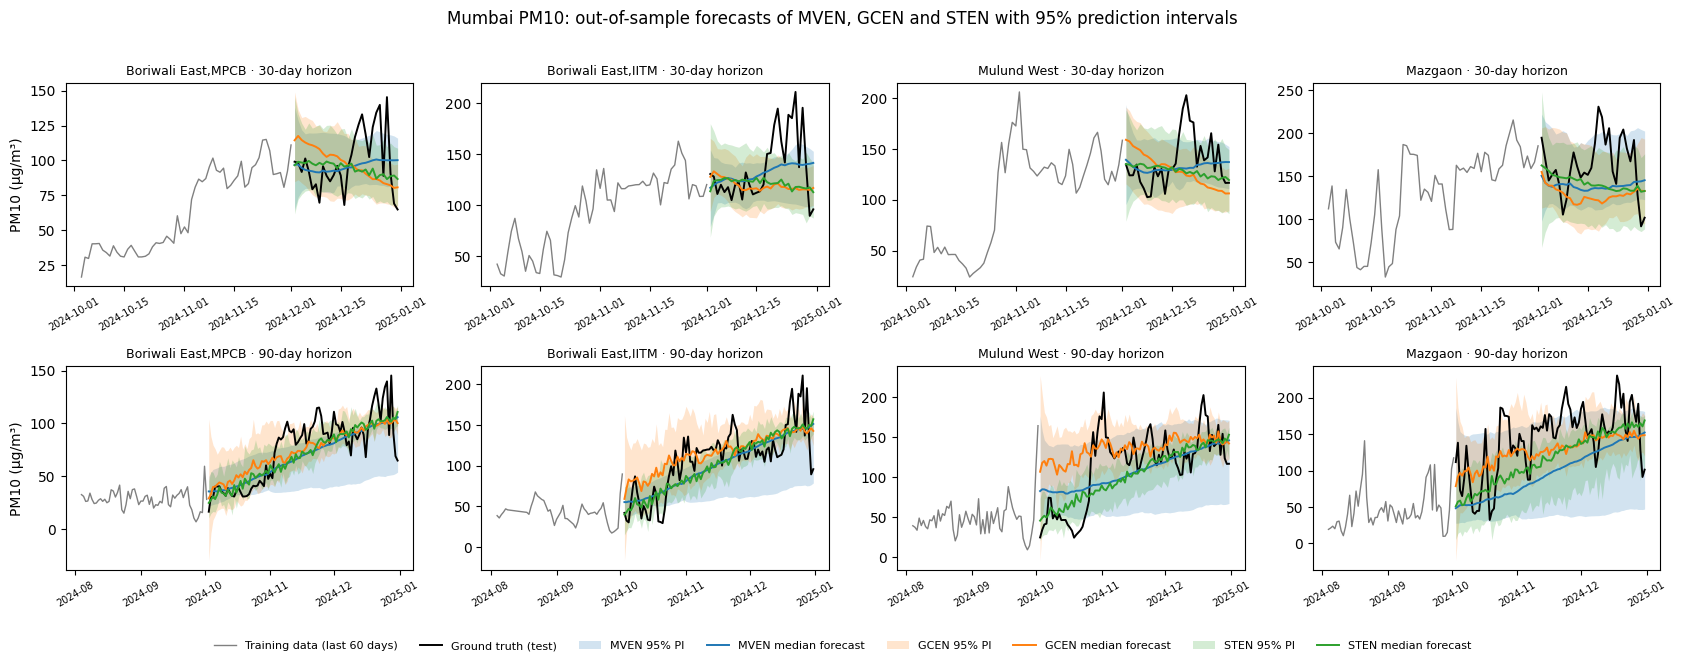

In [37]:
COLORS = {"MVEN": "#1f77b4", "GCEN": "#ff7f0e", "STEN": "#2ca02c"}

def typical_seed(model, h):
    sub = per_seed[(per_seed.model == model) & (per_seed.horizon == h)]
    if sub.empty:
        return None
    return int(sub.loc[(sub.CRPS - sub.CRPS.median()).abs().idxmin(), "seed"])

# choose 4 stations: real measurements in the test period, spread from low to high PM10
clean = [s for s in station_names if not gap_filled[s].iloc[-max(HORIZONS):].any()]
level = data[clean].iloc[-max(HORIZONS):].mean().sort_values()
FIG_STATIONS = [level.index[int(round(i))] for i in np.linspace(0, len(level) - 1, 4)]

fig, axes = plt.subplots(len(HORIZONS), 4, figsize=(17, 3.3 * len(HORIZONS)), squeeze=False)
for i, h in enumerate(HORIZONS):
    ts = T - h
    test_days = data.index[ts:]
    for j, station in enumerate(FIG_STATIONS):
        ax = axes[i, j]
        k = station_names.index(station)
        ax.plot(data.index[ts - 60:ts], data[station].iloc[ts - 60:ts], color="grey", lw=1, label="Training data (last 60 days)")
        ax.plot(test_days, data[station].iloc[ts:], color="black", lw=1.4, label="Ground truth (test)")
        for model in ENGRESSION:
            seed = typical_seed(model, h)
            if seed is None:
                continue
            samples = load_result(model, h, seed)["samples"][:, :, k]
            low, median, high = np.quantile(samples, [0.025, 0.5, 0.975], axis=0)
            ax.fill_between(test_days, low, high, color=COLORS[model], alpha=0.2, lw=0, label=f"{model} 95% PI")
            ax.plot(test_days, median, color=COLORS[model], lw=1.4, label=f"{model} median forecast")
        ax.set_title(f"{station} · {h}-day horizon", fontsize=9)
        ax.tick_params(axis="x", labelrotation=30, labelsize=7)
        if j == 0:
            ax.set_ylabel("PM10 (µg/m³)")
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=len(names), fontsize=8, frameon=False)
fig.suptitle("Mumbai PM10: out-of-sample forecasts of MVEN, GCEN and STEN with 95% prediction intervals")
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
fig.savefig(OUT_DIR / "figure_forecasts.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / "figure_forecasts.pdf", bbox_inches="tight")
plt.show()

## Cell 28: Extra figure: calibration (PIT plots, paper's Fig. 8)
For each observed value we compute which share of the 100 samples lies below it (the PIT). If the forecasts are well calibrated these shares are spread evenly, and the line follows the red diagonal.

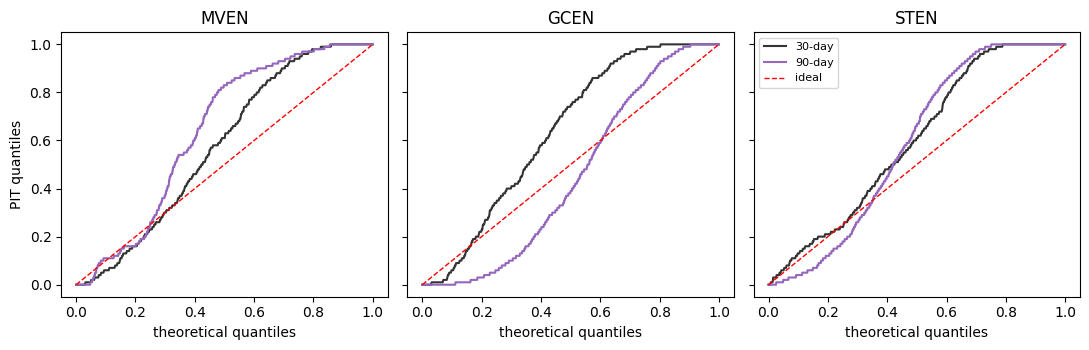

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, model in zip(axes, ENGRESSION):
    for h, color in zip(HORIZONS, ["#333333", "#9467bd"]):
        seed = typical_seed(model, h)
        if seed is None:
            continue
        samples = load_result(model, h, seed)["samples"]
        pit = np.sort((samples <= prep[h]["y_test"][None]).mean(0).ravel())
        ax.plot(np.linspace(0, 1, len(pit)), pit, color=color, lw=1.5, label=f"{h}-day")
    ax.plot([0, 1], [0, 1], "r--", lw=1, label="ideal")
    ax.set_title(model); ax.set_xlabel("theoretical quantiles")
axes[0].set_ylabel("PIT quantiles"); axes[-1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "figure_pit.png", dpi=300, bbox_inches="tight"); plt.show()

## Cell 29: Extra figure: STEN's spatial lag importance (paper's Fig. 11)
How much STEN relies on each spatial lag: l = 0 the station itself, l = 1 its neighbours, l = 2 the neighbours' neighbours, ...
Measured as the size of the learned weights ‖Φₗ‖ in %, mean ± sd over seeds.

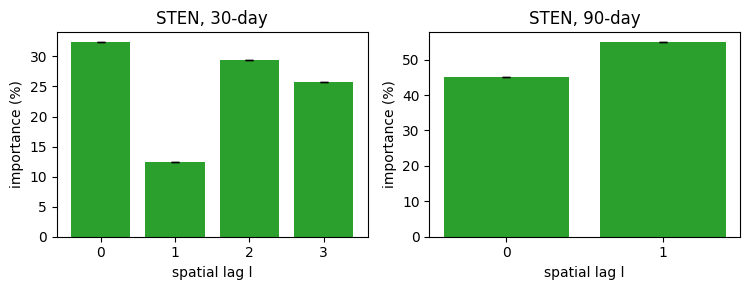

In [39]:
rows = []
for h in HORIZONS:
    for seed in SEEDS:
        if result_file("STEN", h, seed).exists():
            for l, v in enumerate(load_result("STEN", h, seed)["extra"].get("lag_importance_pct", [])):
                rows.append({"horizon": h, "lag": l, "pct": v})
if rows:
    lag = pd.DataFrame(rows).groupby(["horizon", "lag"]).pct.agg(["mean", "std"]).reset_index()
    lag.to_csv(OUT_DIR / "lag_importance.csv", index=False)
    fig, axes = plt.subplots(1, len(HORIZONS), figsize=(3.8 * len(HORIZONS), 3), squeeze=False)
    for ax, h in zip(axes[0], HORIZONS):
        sub = lag[lag.horizon == h]
        ax.bar(sub.lag, sub["mean"], yerr=sub["std"].fillna(0), color="#2ca02c", capsize=3)
        ax.set_xticks(sub.lag); ax.set_xlabel("spatial lag l"); ax.set_ylabel("importance (%)"); ax.set_title(f"STEN, {h}-day")
    fig.tight_layout(); fig.savefig(OUT_DIR / "figure_lag_importance.png", dpi=300, bbox_inches="tight"); plt.show()

## Cell 30: Extra figure: which stations STEN combines
Map of the 17 stations. Blue lines: every pair is connected, thicker = larger weight $1/d^\alpha$ (with the tuned α of each horizon).
Green circles and arrows: how much each station contributes to the neighbour average of the most central station (★).

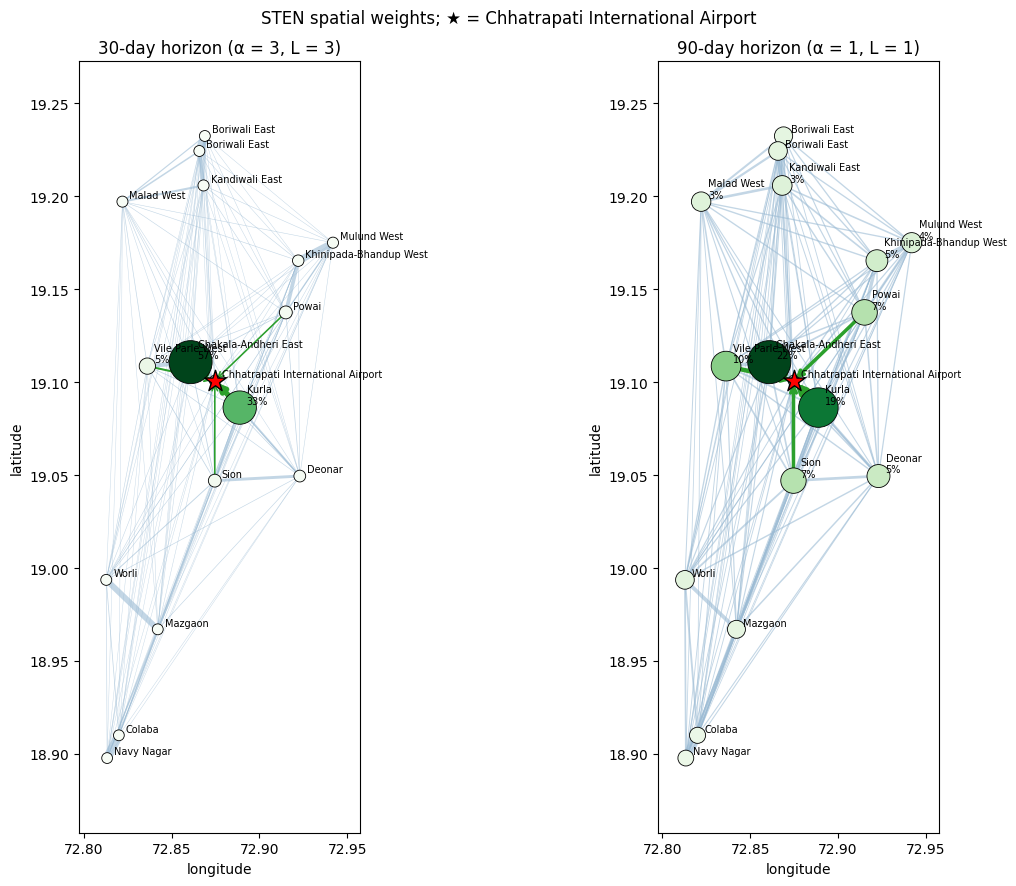

In [40]:
from matplotlib.collections import LineCollection
x, y = stations["LONG"].values, stations["LAT"].values
centre = int(np.argmin(dist.sum(1)))
short = lambda n: n.split(",")[0]
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(6 * len(HORIZONS), 9), squeeze=False)
for ax, h in zip(axes[0], HORIZONS):
    if "STEN" not in BEST or h not in BEST["STEN"]:
        continue
    alpha, L = BEST["STEN"][h]["alpha"], BEST["STEN"][h]["L"]
    W = 1 / np.where(dist == 0, np.inf, dist) ** alpha; W = W / W.sum(1, keepdims=True)
    S = (W + W.T) / 2
    pairs = [(i, j) for i in range(N) for j in range(i + 1, N)]
    widths = np.array([S[i, j] for i, j in pairs])
    ax.add_collection(LineCollection([[(x[i], y[i]), (x[j], y[j])] for i, j in pairs],
                                     linewidths=0.3 + 6 * widths / widths.max(), colors="#9bbbd4", alpha=0.6))
    w = W[centre]
    for j in np.argsort(-w)[:5]:
        ax.annotate("", xy=(x[centre], y[centre]), xytext=(x[j], y[j]),
                    arrowprops=dict(arrowstyle="->", color="#2ca02c", lw=1 + 5 * w[j] / w.max()))
    ax.scatter(x, y, s=60 + 900 * w / w.max(), c=w, cmap="Greens", edgecolor="black", lw=0.6, zorder=3, vmin=0)
    ax.scatter(x[centre], y[centre], s=260, marker="*", color="red", edgecolor="black", zorder=4)
    for i in range(N):
        ax.text(x[i] + 0.004, y[i] + 0.002, short(station_names[i]) + (f"\n{100 * w[i]:.0f}%" if i != centre and w[i] >= 0.03 else ""), fontsize=7)
    ax.set_title(f"{h}-day horizon (α = {alpha}, L = {L})"); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    ax.set_aspect(1 / np.cos(np.radians(19.1))); ax.margins(0.12)
fig.suptitle(f"STEN spatial weights; ★ = {short(station_names[centre])}")
fig.tight_layout(); fig.savefig(OUT_DIR / "figure_station_weights.png", dpi=200, bbox_inches="tight"); plt.show()

---
# Part 8: Save
All settings and package versions go into `run_info.json`, and the whole folder is zipped. On Kaggle the files appear under **Output** after the committed run.

In [41]:
from importlib.metadata import version
def safe_version(p):
    try:
        return version(p)
    except Exception:
        return "n/a"

info = {"dataset": "Mumbai PM10", "data_md5": data_md5, "stations": station_names, "horizons": HORIZONS, "seeds": SEEDS,
        "lookback": LOOKBACK, "epochs": EPOCHS, "n_samples": N_SAMPLES, "n_repeats": N_REPEATS,
        "tuned_hyperparameters": BEST, "gcen_method": GCEN_METHOD, "tuning_files": summary.to_dict("records"),
        "baselines": {"deepar_epochs": DEEPAR_EPOCHS, "itransformer_epochs": ITRANS_EPOCHS, "diffstg_epochs": DIFFSTG_EPOCHS,
                      "diffstg_steps": DIFFSTG_STEPS, "stesn_hp": STESN_HP, "stesn_members": STESN_MEMBERS,
                      "gpgp_max_iter": GPGP_MAX_ITER, "diffstg_graph": "GCEN graph"},
        "figure_stations": FIG_STATIONS, "failed": FAILED, "quick_run": QUICK_RUN,
        "versions": {p: safe_version(p) for p in ["stengression", "torch", "darts", "gluonts", "lightning", "numpy", "pandas"]},
        "device": str(device), "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "python": platform.python_version()}
json.dump(info, open(OUT_DIR / "run_info.json", "w"), indent=2, default=str)
shutil.make_archive(str(OUT_DIR), "zip", root_dir=OUT_DIR)
print("Saved:", sorted(p.name for p in OUT_DIR.iterdir()))
print("Zip:", str(OUT_DIR) + ".zip")

Saved: ['figure_forecasts.pdf', 'figure_forecasts.png', 'figure_lag_importance.png', 'figure_pit.png', 'figure_station_weights.png', 'lag_importance.csv', 'metrics_per_seed.csv', 'run_info.json', 'samples', 'table_evaluation.csv', 'table_evaluation.tex', 'table_evaluation.xlsx', 'table_times.csv']
Zip: /kaggle/working/Mumbai_PM10_testing.zip
